**Tugas Exercise 7 — Unsupervised Clustering pada Artikel Substack**

Anggota Kelompok:
1. Azzahra Aulia Mansur (25031554223)
2. Neysa Maldy Amantha (25031554078)

## 1. Import Library

In [86]:
import warnings
warnings.filterwarnings("ignore")

## 2. Feature Engineering — TF-IDF

In [87]:
from sklearn.feature_extraction.text import TfidfVectorizer

import pandas as pd
df = pd.read_csv('preprocessed.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

## Unsupervised: KMeans

In [88]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [89]:
k = range(1,7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10) # jumlah cluster akan di looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[28.140230935433536, 26.60294254057979, 25.492617913059096, 24.235042436630728, 23.262024771374946, 22.18267597362391]


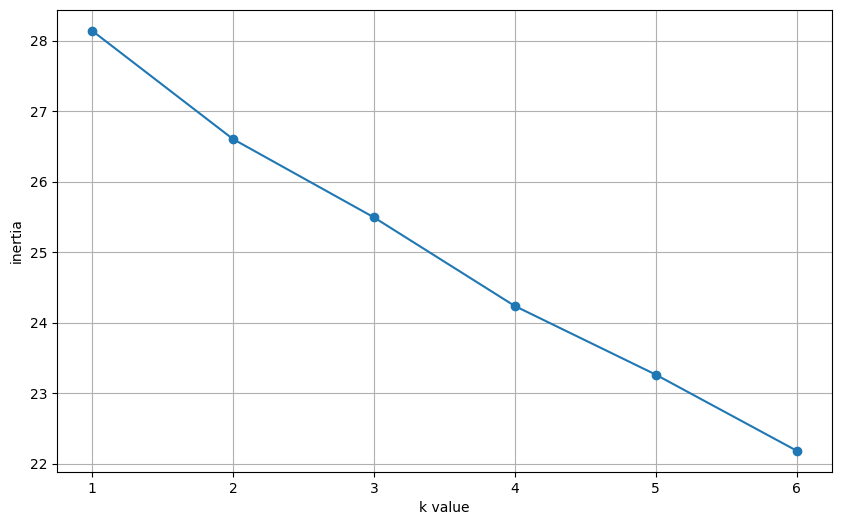

In [90]:
plt.figure(figsize=(10,6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

**Menentukan jumlah cluster**


In [91]:
n_clusters = 4

# K-Means membutuhkan jumlah sampel minimal sebanyak n_clusters.
if len(df_FE) < n_clusters:
    raise ValueError(
        f"Jumlah paragraf hanya {len(df_FE)}, sedangkan materi dosen menggunakan "
        f"n_clusters={n_clusters}. Periksa kembali hasil preprocessing/segmentasi."
    )

In [92]:
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

KMeans(n_clusters=4, random_state=10)

In [93]:
df['Kmeans_label'] = kM.labels_
df.head()

,Id,Sentiment,text,prepro,Kmeans_label
0,1,positive,Hari ini kau melihat banyak lowongan pekerjaan...,hari kau lihat banyak lowong kerja entah kau r...,1
1,2,negative,"Kau melihat banyak beasiswa, lalu mulai menghi...",kau lihat banyak beasiswa lalu mulai hitung mu...,1
2,3,positive,Kemarin kau bahkan sempat membayangkan punya u...,kemarin kau bahkan sempat bayang punya usaha s...,1
3,4,positive,Begitulah kadang kita menjalani hidup. Kesempa...,kadang jalan hidup sempat datang terlalu sibuk...,0
4,5,negative,Kau takut mendaftar karena takut ditolak. Kau ...,kau takut daftar takut tolak kau takut coba ta...,2


**Silhouette Score**

In [94]:
from sklearn import metrics
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.01324516879802536)

**Word Cloud**

Kmeans for cluster 0


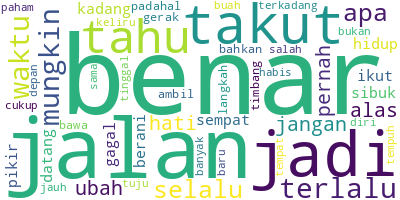

In [95]:
c = 0
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


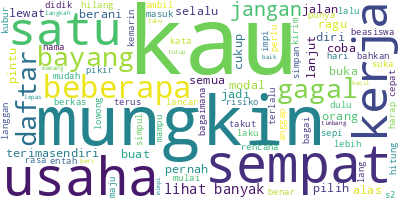

In [96]:
c = 1
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


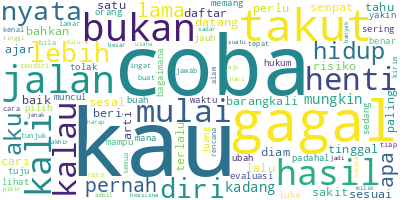

In [97]:
c = 2
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


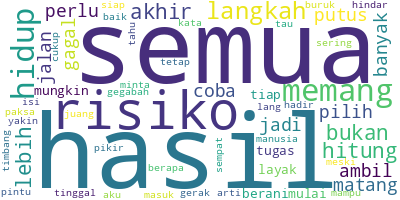

In [98]:
c = 3
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

## Unsupervised: Hierarchical

In [99]:
from scipy.cluster.hierarchy import dendrogram, linkage

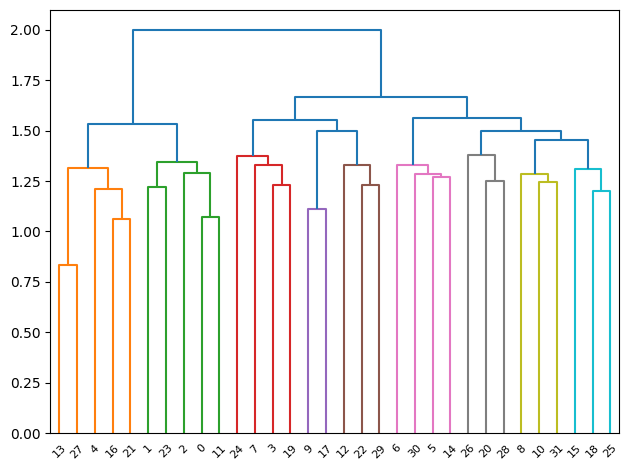

In [100]:
linkage_data = linkage(df_FE, method = 'ward', metric = 'euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

https://scikit-learn.org/dev/modules/generated/sklearn.cluster.AgglomerativeClustering.html

In [101]:
from sklearn.cluster import AgglomerativeClustering
hierarchical_cluster = AgglomerativeClustering(n_clusters = n_clusters, linkage = 'ward')
labels = hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

In [102]:
df.head()

,Id,Sentiment,text,prepro,Kmeans_label,Ward_label
0,1,positive,Hari ini kau melihat banyak lowongan pekerjaan...,hari kau lihat banyak lowong kerja entah kau r...,1,1
1,2,negative,"Kau melihat banyak beasiswa, lalu mulai menghi...",kau lihat banyak beasiswa lalu mulai hitung mu...,1,1
2,3,positive,Kemarin kau bahkan sempat membayangkan punya u...,kemarin kau bahkan sempat bayang punya usaha s...,1,1
3,4,positive,Begitulah kadang kita menjalani hidup. Kesempa...,kadang jalan hidup sempat datang terlalu sibuk...,0,0
4,5,negative,Kau takut mendaftar karena takut ditolak. Kau ...,kau takut daftar takut tolak kau takut coba ta...,2,1


**Silhouette Score**

In [103]:
from sklearn import metrics
labels = pred_agc
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.03829083972081417)

**Word Cloud**

Hierarchical for cluster 0


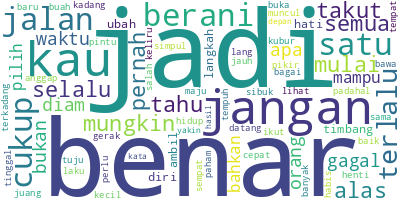

In [104]:
c = 0
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

# Sentiment-Supervised

Sentiment positive


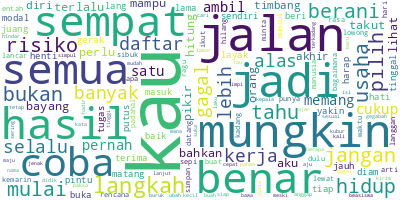

In [105]:
from wordcloud import WordCloud
c = 'positive'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

Sentiment negative


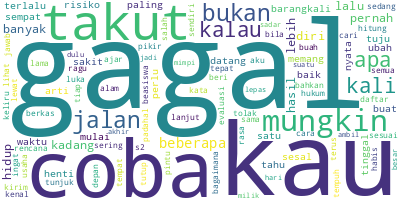

In [106]:
from wordcloud import WordCloud
c = 'negative'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

In [107]:
import pandas as pd
df = pd.read_csv('preprocessed.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']

# Mengubah teks menjadi matriks TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
vecs = vectorizer.fit_transform(df_pre)
vecs

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 457 stored elements and shape (32, 181)>

In [108]:
# Classify
X = vecs # FE result
y = df['Sentiment']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[0 2]
 [0 8]]
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.80      1.00      0.89         8

    accuracy                           0.80        10
   macro avg       0.40      0.50      0.44        10
weighted avg       0.64      0.80      0.71        10



## Analisis Hasil

Analisis hasil clustering berdasarkan output notebook:

1. Amati titik siku pada grafik Elbow Method.
2. Perhatikan nilai Silhouette Score K-Means dan Hierarchical.
3. Amati Word Cloud untuk melihat kata-kata dominan di setiap cluster.
4. Cocokkan label cluster dengan isi paragraf (`text`) untuk memberi interpretasi topik.

Nomor cluster (0, 1, 2, 3) hanya label dari algoritma, bukan urutan topik atau tingkat kepentingan.

In [112]:
# Memulihkan kolom label clustering yang hilang akibat df di-overwrite pada sel klasifikasi
df['Kmeans_label'] = kM.labels_
df['Ward_label'] = pred_agc

# Menampilkan hasil clustering
display(df[[
    "Id",
    "text",
    "prepro",
    "Kmeans_label",
    "Ward_label"
]])

# Menyimpan hasil clustering
df.to_csv("preprocessed.csv", index=False)

print("File hasil clustering berhasil disimpan!")

,Id,text,prepro,Kmeans_label,Ward_label
0,1,Hari ini kau melihat banyak lowongan pekerjaan...,hari kau lihat banyak lowong kerja entah kau r...,1,1
1,2,"Kau melihat banyak beasiswa, lalu mulai menghi...",kau lihat banyak beasiswa lalu mulai hitung mu...,1,1
2,3,Kemarin kau bahkan sempat membayangkan punya u...,kemarin kau bahkan sempat bayang punya usaha s...,1,1
3,4,Begitulah kadang kita menjalani hidup. Kesempa...,kadang jalan hidup sempat datang terlalu sibuk...,0,0
4,5,Kau takut mendaftar karena takut ditolak. Kau ...,kau takut daftar takut tolak kau takut coba ta...,2,1
5,6,Barangkali yang paling menyakitkan bukanlah ke...,barangkali paling sakit bukan gagal barangkali...,2,3
6,7,Sebab kegagalan hanya meninggalkan luka untuk ...,gagal tinggal luka sesal pernah coba sering ka...,2,3
7,8,Ia muncul diam-diam ketika melihat orang lain ...,muncul diam diam lihat orang benar pernah juan...,2,0
8,9,"Tentu saja, mengambil risiko bukan berarti ber...",ambil risiko bukan arti jalan hitung aku minta...,3,2
9,10,Tetapi jangan sampai pertimbangan berubah menj...,jangan timbang ubah jadi takut jangan hati hat...,0,0


File hasil clustering berhasil disimpan!
